# Pre-procesamiento · Histórico de Ventas CLV

**Fuente:** `Datos_Complementarios_CLV.xlsx` → hoja 3 `Histórico_Ventas` (ventas de productos odontológicos a doctores y consultorios).

**Objetivo:** dejar un dataset limpio, numérico y estandarizado, listo para modelos de regresión lineal simple/múltiple y regresión logística.

**Pasos**
1. Carga y EDA breve
2. Limpieza de texto y revisión de valores nulos (reales y ocultos) + imputación
3. Outliers con el método IQR → se convierten a nulos → se imputan con media o mediana
4. Transformación y estandarización con scikit-learn
5. Exportación a `historico_ventas_clv_listo.csv`

## 1. Carga de datos y EDA breve

In [1]:
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

In [2]:
# La hoja 3 se carga por posición para evitar problemas con el acento del nombre "Histórico_Ventas"
df = pd.read_excel("Datos_Complementarios_CLV.xlsx", sheet_name=2)

# La columna "estado" viene con espacios al final en el Excel; se limpian todos los nombres
df.columns = df.columns.str.strip()

print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head()

Filas: 21,632 | Columnas: 14


,folio_abreviado,folio,fecha_documento,articulo_id,nombre_articulo,marca,precio_unitario,total_unidades,total_neto,nombre_cliente,estado,ciudad,cp,vendedor
0,B00,B00013159,15.10.2026,16301346,AIZIR 98 X 14mm OM1,AIDITE,1310.35000,1,1310.35,ARTURO HERNANDEZ SF,Estado de México,Estado de Mexico,55140.0,DIEGO
1,CDF,CDF002643,15.10.2026,7214,"LUMEX DENTINE, A1, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD
2,CDF,CDF002643,15.10.2026,7217,"LUMEX DENTINE, A2, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD
3,CDF,CDF002643,15.10.2026,7223,"LUMEX DENTINE, A3, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD
4,CDF,CDF002643,15.10.2026,7277,"LUMEX ENAMEL, CLEAR, 12 G",VITA,508.62069,1,508.62,ROBERTO CUEVAS DE LOS COBOS,Ciudad de México,CDMX,4210.0,JAVIERCAD


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21632 entries, 0 to 21631
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   folio_abreviado  21632 non-null  object 
 1   folio            21632 non-null  object 
 2   fecha_documento  21632 non-null  object 
 3   articulo_id      21632 non-null  int64  
 4   nombre_articulo  21632 non-null  object 
 5   marca            21632 non-null  object 
 6   precio_unitario  21632 non-null  float64
 7   total_unidades   21632 non-null  int64  
 8   total_neto       21632 non-null  float64
 9   nombre_cliente   21632 non-null  object 
 10  estado           21632 non-null  object 
 11  ciudad           21632 non-null  object 
 12  cp               21140 non-null  float64
 13  vendedor         21632 non-null  object 
dtypes: float64(3), int64(2), object(9)
memory usage: 2.3+ MB


In [4]:
# Estadísticos de las variables numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
articulo_id,21632.0,3.393504e+06,1.041444e+07,3488.0,7847.000000,8381.000000,212234.0000,7.338899e+07
precio_unitario,21632.0,4.337612e+03,4.283812e+04,0.0,172.413793,614.689655,1284.4800,2.170948e+06
total_unidades,21632.0,2.792946e+00,5.276435e+00,1.0,1.000000,1.000000,2.0000,1.810000e+02
total_neto,21632.0,5.388638e+03,4.317075e+04,0.0,200.000000,948.280000,2148.4975,2.170948e+06
cp,21140.0,5.033607e+04,2.851074e+04,500.0,22500.000000,54190.000000,76020.0000,1.570000e+05


In [5]:
# Cardinalidad de las variables de texto
cols_texto = df.select_dtypes(include="object").columns
pd.DataFrame({
    "unicos": df[cols_texto].nunique(),
    "ejemplo": df[cols_texto].iloc[0],
})

,unicos,ejemplo
folio_abreviado,11,B00
folio,5345,B00013159
fecha_documento,204,15.10.2026
nombre_articulo,2130,AIZIR 98 X 14mm OM1
marca,25,AIDITE
nombre_cliente,1685,ARTURO HERNANDEZ SF
estado,53,Estado de México
ciudad,273,Estado de Mexico
vendedor,77,DIEGO


In [6]:
# Rango de fechas, duplicados exactos y registros con precio 0
fechas = pd.to_datetime(df["fecha_documento"], format="%d.%m.%Y")
print(f"Rango de fechas        : {fechas.min().date()} → {fechas.max().date()}")
print(f"Filas duplicadas exactas: {df.duplicated().sum()}")
print(f"Filas con precio_unitario = 0: {(df['precio_unitario'] == 0).sum()}")

Rango de fechas        : 2026-01-05 → 2026-10-15
Filas duplicadas exactas: 185
Filas con precio_unitario = 0: 1612


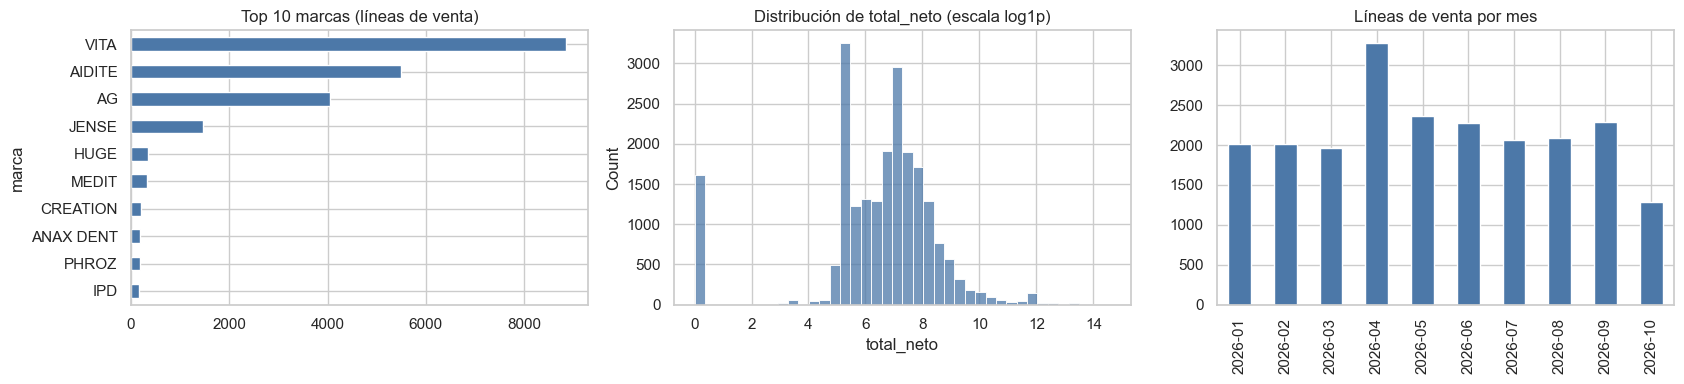

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))

df["marca"].str.strip().str.upper().value_counts().head(10).sort_values().plot.barh(ax=ax[0], color="#4C78A8")
ax[0].set_title("Top 10 marcas (líneas de venta)")

sns.histplot(np.log1p(df["total_neto"]), bins=40, ax=ax[1], color="#4C78A8")
ax[1].set_title("Distribución de total_neto (escala log1p)")

fechas.dt.to_period("M").value_counts().sort_index().plot.bar(ax=ax[2], color="#4C78A8")
ax[2].set_title("Líneas de venta por mes")
ax[2].set_xlabel("")

plt.tight_layout()
plt.show()

**Hallazgos del EDA**

- 21,632 líneas de venta de enero a octubre de 2026, en 14 columnas.
- El único nulo "real" está en `cp` (492 filas). Hay además marcadores de faltante escondidos en texto (`Sin Estado`, `Sin Ciudad`), que se revisan abajo.
- `estado` y `ciudad` tienen variantes del mismo valor por mayúsculas/acentos (`PUEBLA` vs `Puebla`, `MÉXICO` vs `Estado de México`).
- Las tres variables numéricas continuas (`precio_unitario`, `total_unidades`, `total_neto`) están muy sesgadas a la derecha: la mediana es mucho menor que la media y el máximo (kits de más de $2 millones) está muy lejos del tercer cuartil.
- Hay 1,612 líneas con `precio_unitario = 0` (productos bonificados/regalo). No son nulos ni errores, son ventas reales a $0, por lo que se conservan.
- **Duplicados exactos (185):** el archivo no trae un identificador de línea dentro del folio, así que una misma partida repetida (p. ej. 6 líneas idénticas de una promo) puede ser una venta legítima. Se **conservan** para no eliminar ventas reales.

## 2. Limpieza de texto y valores nulos

### 2.1 Normalización de texto y fecha

Se unifican mayúsculas, acentos y espacios para que `PUEBLA` y `Puebla` cuenten como una sola categoría. Después se detectan los marcadores de faltante (`Sin Estado`, `Sin Ciudad`) y se convierten en nulos reales.

In [8]:
def normalizar_texto(valor):
    """Mayúsculas, sin acentos, sin espacios repetidos. Respeta los nulos."""
    if pd.isna(valor):
        return valor
    valor = unicodedata.normalize("NFKD", str(valor)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", valor).strip().upper()

for col in ["marca", "estado", "ciudad", "vendedor"]:
    antes = df[col].nunique()
    df[col] = df[col].map(normalizar_texto)
    print(f"{col:9s}: {antes:3d} → {df[col].nunique():3d} categorías")

# "MEXICO" como estado es el Estado de México (la CDMX aparece aparte como "CIUDAD DE MEXICO")
df["estado"] = df["estado"].replace({"MEXICO": "ESTADO DE MEXICO"})

# Fecha como datetime
df["fecha_documento"] = pd.to_datetime(df["fecha_documento"], format="%d.%m.%Y")

marca    :  25 →  25 categorías
estado   :  53 →  34 categorías
ciudad   : 273 → 250 categorías
vendedor :  77 →  77 categorías


In [9]:
# Marcadores de faltante escondidos como texto → nulos reales
df[["estado", "ciudad"]] = df[["estado", "ciudad"]].replace({"SIN ESTADO": np.nan, "SIN CIUDAD": np.nan})

### 2.2 Revisión de nulos

In [10]:
nulos = pd.DataFrame({"nulos": df.isna().sum(), "% nulos": (df.isna().mean() * 100).round(2)})
nulos[nulos["nulos"] > 0]

,nulos,% nulos
estado,138,0.64
ciudad,138,0.64
cp,492,2.27


In [11]:
# ¿Se traslapan los faltantes de ubicación?
print("estado y ciudad nulos a la vez:", (df["estado"].isna() & df["ciudad"].isna()).sum())
print("estado nulo, ciudad conocida  :", (df["estado"].isna() & df["ciudad"].notna()).sum())
print("ciudad nula, estado conocido  :", (df["ciudad"].isna() & df["estado"].notna()).sum())
print("cp nulo con ciudad conocida   :", (df["cp"].isna() & df["ciudad"].notna()).sum())
print("estado nulo pero cp conocido  :", (df["estado"].isna() & df["cp"].notna()).sum())

estado y ciudad nulos a la vez: 138
estado nulo, ciudad conocida  : 0
ciudad nula, estado conocido  : 0
cp nulo con ciudad conocida   : 454
estado nulo pero cp conocido  : 100


### 2.3 Estrategia de imputación según la naturaleza de cada variable

| Variable | Naturaleza | Estrategia |
|---|---|---|
| `estado`, `ciudad` | Categórica (geográfica) | **Moda dentro del grupo relacionado**. Los faltantes de estado y ciudad coinciden en las mismas filas, así que se infieren desde el `cp` (si existe): el valor más frecuente en ese código postal. Si tampoco hay `cp`, la ciudad se infiere del estado y, en último caso, moda global. |
| `cp` | **Código** postal (numérico solo en apariencia: promediarlo no tiene sentido) | **Moda** dentro de la ciudad; si no alcanza, dentro del estado; si no, moda global. |

La media/mediana no aplica aquí: son variables nominales, no cantidades. Las columnas numéricas continuas se tratan en la sección 3.

In [12]:
def moda(serie):
    m = serie.mode()
    return m.iloc[0] if len(m) else np.nan

def imputar_moda_por_grupo(frame, col, grupo):
    """Rellena los nulos de `col` con la moda de `col` dentro de cada valor de `grupo`."""
    moda_por_grupo = frame.groupby(grupo)[col].agg(moda)
    return frame[col].fillna(frame[grupo].map(moda_por_grupo))

# estado ← ciudad, luego ← cp
df["estado"] = imputar_moda_por_grupo(df, "estado", "ciudad")
df["estado"] = imputar_moda_por_grupo(df, "estado", "cp")

# ciudad ← cp, luego ← estado
df["ciudad"] = imputar_moda_por_grupo(df, "ciudad", "cp")
df["ciudad"] = imputar_moda_por_grupo(df, "ciudad", "estado")

# cp ← ciudad, luego ← estado
df["cp"] = imputar_moda_por_grupo(df, "cp", "ciudad")
df["cp"] = imputar_moda_por_grupo(df, "cp", "estado")

# Respaldo: moda global para lo que haya quedado sin grupo de referencia
for col in ["estado", "ciudad", "cp"]:
    df[col] = df[col].fillna(moda(df[col]))

df["cp"] = df["cp"].astype(int)   # un código postal es entero

In [13]:
print("Nulos restantes en todo el dataset:", int(df.isna().sum().sum()))
df.isna().sum().to_frame("nulos").T

Nulos restantes en todo el dataset: 0


,folio_abreviado,folio,fecha_documento,articulo_id,nombre_articulo,marca,precio_unitario,total_unidades,total_neto,nombre_cliente,estado,ciudad,cp,vendedor
nulos,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 3. Outliers con el método IQR

Para cada variable numérica continua (`precio_unitario`, `total_unidades`, `total_neto`):

- `IQR = Q3 − Q1`
- Límites: `[Q1 − 1.5·IQR , Q3 + 1.5·IQR]`
- Todo valor fuera de los límites se convierte a **nulo** y después se imputa.

No se aplica IQR a `cp` ni a `articulo_id`, porque son códigos identificadores y no cantidades.

In [14]:
cols_num = ["precio_unitario", "total_unidades", "total_neto"]

def limites_iqr(serie, k=1.5):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

resumen = []
for col in cols_num:
    inf, sup = limites_iqr(df[col])
    n_out = ((df[col] < inf) | (df[col] > sup)).sum()
    resumen.append({
        "variable": col, "límite_inf": inf, "límite_sup": sup,
        "outliers": n_out, "% outliers": round(n_out / len(df) * 100, 2),
        "media": df[col].mean(), "mediana": df[col].median(), "asimetría": df[col].skew(),
    })
resumen_iqr = pd.DataFrame(resumen).set_index("variable").round(2)
resumen_iqr

,límite_inf,límite_sup,outliers,% outliers,media,mediana,asimetría
variable,,,,,,,
precio_unitario,-1495.69,2952.58,1076,4.97,4337.61,614.69,24.55
total_unidades,-0.50,3.50,3659,16.91,2.79,1.00,10.03
total_neto,-2722.75,5071.24,2150,9.94,5388.64,948.28,24.05


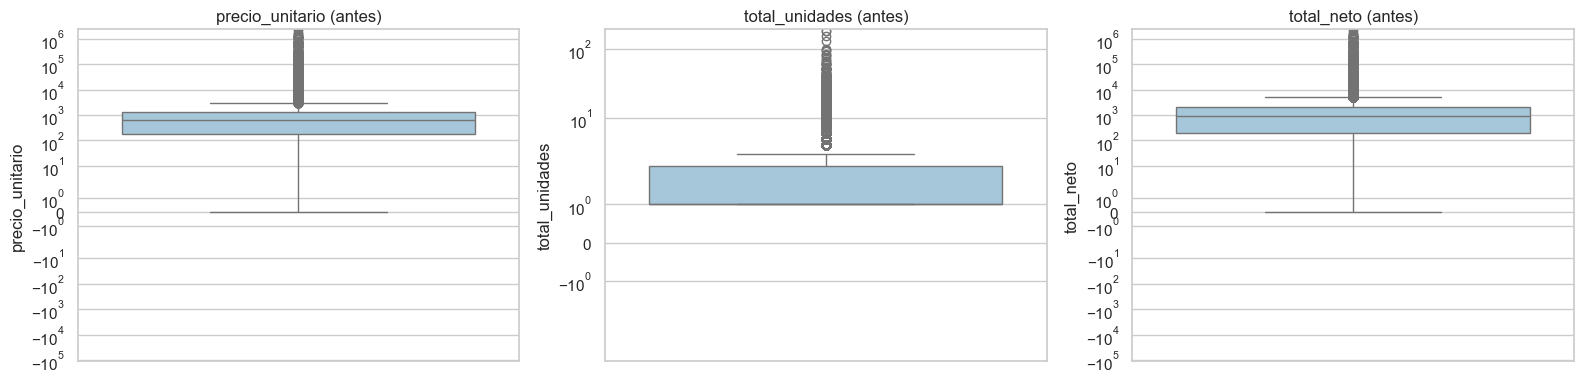

In [15]:
# Antes: boxplots (eje symlog porque hay valores en 0 y un rango enorme)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, cols_num):
    sns.boxplot(y=df[col], ax=a, color="#9ecae1")
    a.set_yscale("symlog")
    a.set_title(f"{col} (antes)")
plt.tight_layout()
plt.show()

In [16]:
# Outliers → NaN (los límites se calculan sobre los datos originales de cada columna)
for col in cols_num:
    inf, sup = limites_iqr(df[col])
    df.loc[(df[col] < inf) | (df[col] > sup), col] = np.nan

df[cols_num].isna().sum().to_frame("nulos tras marcar outliers").T

,precio_unitario,total_unidades,total_neto
nulos tras marcar outliers,1076,3659,2150


### Elección entre media y mediana

Se decide con los datos: se mide la asimetría de lo que **queda** tras retirar los outliers. Si la distribución sigue sesgada (|asimetría| > 0.5) la media seguiría arrastrada por la cola larga y se usa la **mediana**; si es razonablemente simétrica se usa la **media**.

In [17]:
estrategia = {}
for col in cols_num:
    asim = df[col].skew()
    estrategia[col] = "median" if abs(asim) > 0.5 else "mean"
    print(f"{col:16s} asimetría = {asim:5.2f}  →  {estrategia[col]}")

precio_unitario  asimetría =  0.76  →  median
total_unidades   asimetría =  1.57  →  median
total_neto       asimetría =  1.31  →  median


In [18]:
for col in cols_num:
    imputador = SimpleImputer(strategy=estrategia[col])
    df[col] = imputador.fit_transform(df[[col]]).ravel()
    print(f"{col:16s} valor de imputación ({estrategia[col]}): {imputador.statistics_[0]:.2f}")

print("\nNulos restantes en todo el dataset:", int(df.isna().sum().sum()))

precio_unitario  valor de imputación (median): 508.62
total_unidades   valor de imputación (median): 1.00
total_neto       valor de imputación (median): 783.71

Nulos restantes en todo el dataset: 0


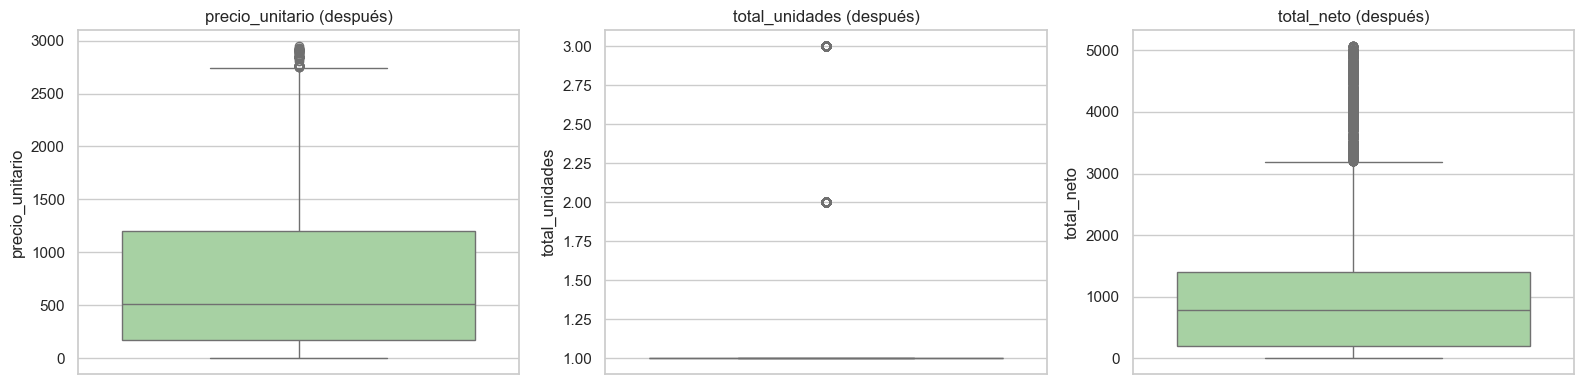

,count,mean,std,min,25%,50%,75%,max
precio_unitario,21632.0,684.32,600.98,0.0,172.41,508.62,1200.00,2948.27
total_unidades,21632.0,1.29,0.58,1.0,1.00,1.00,1.00,3.00
total_neto,21632.0,1082.95,1082.80,0.0,200.00,783.71,1396.56,5068.98


In [19]:
# Después: mismos boxplots, ya sin outliers
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, cols_num):
    sns.boxplot(y=df[col], ax=a, color="#a1d99b")
    a.set_title(f"{col} (después)")
plt.tight_layout()
plt.show()

df[cols_num].describe().T.round(2)

**Nota:** el criterio 1.5·IQR es agresivo en `total_unidades` (Q1 = 1 y Q3 = 2, por lo que cualquier venta de 4 o más piezas cae como outlier). Se aplica tal cual porque ese es el método solicitado; el porcentaje afectado de cada variable queda documentado en la tabla de arriba.

## 4. Transformación y estandarización con scikit-learn

**Variables derivadas de la fecha.** Un modelo de regresión no puede usar una fecha en bruto, así que se extraen `mes`, `dia_semana` y `dia_mes`.

**Variables que se descartan** (no aportan señal generalizable a una regresión):

| Variable | Motivo |
|---|---|
| `folio`, `articulo_id`, `nombre_articulo`, `nombre_cliente` | Identificadores de muy alta cardinalidad (miles de valores únicos). `marca` ya resume el producto. |
| `ciudad`, `cp` | Alta cardinalidad y redundantes con `estado`, que ya captura la geografía. |
| `fecha_documento` | Sustituida por `mes`, `dia_semana` y `dia_mes`. |

**Transformaciones**
- Numéricas (`precio_unitario`, `total_unidades`, `total_neto`, `mes`, `dia_semana`, `dia_mes`) → `StandardScaler` (media 0, desviación 1).
- Categóricas (`folio_abreviado`, `marca`, `estado`, `vendedor`) → `OneHotEncoder` con `drop="first"` (evita multicolinealidad en la regresión lineal) y `min_frequency=0.01` (las categorías con menos de 1 % de las filas se agrupan en una sola, para no inflar el número de columnas).

In [20]:
df_modelo = df.copy()
df_modelo["mes"] = df_modelo["fecha_documento"].dt.month
df_modelo["dia_semana"] = df_modelo["fecha_documento"].dt.dayofweek   # 0 = lunes
df_modelo["dia_mes"] = df_modelo["fecha_documento"].dt.day

cols_descartar = ["folio", "articulo_id", "nombre_articulo", "nombre_cliente",
                  "ciudad", "cp", "fecha_documento"]
df_modelo = df_modelo.drop(columns=cols_descartar)

cols_numericas = ["precio_unitario", "total_unidades", "total_neto", "mes", "dia_semana", "dia_mes"]
cols_categoricas = ["folio_abreviado", "marca", "estado", "vendedor"]

print({c: df_modelo[c].nunique() for c in cols_categoricas})

{'folio_abreviado': 11, 'marca': 25, 'estado': 32, 'vendedor': 77}


In [21]:
preprocesador = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), cols_numericas),
        ("cat", OneHotEncoder(drop="first", min_frequency=0.01,
                              handle_unknown="infrequent_if_exist", sparse_output=False), cols_categoricas),
    ],
    verbose_feature_names_out=False,
)

matriz = preprocesador.fit_transform(df_modelo)

# Nombres de columnas "seguros" (sin espacios ni símbolos) para usarlos luego en modelos/fórmulas
nombres = [re.sub(r"[^0-9a-zA-Z_]+", "_", n).strip("_") for n in preprocesador.get_feature_names_out()]
df_listo = pd.DataFrame(matriz, columns=nombres)

# Las dummies son 0/1 → enteros
cols_dummy = [c for c in df_listo.columns if c not in cols_numericas]
df_listo[cols_dummy] = df_listo[cols_dummy].astype(int)

print(f"Dataset final: {df_listo.shape[0]:,} filas × {df_listo.shape[1]} columnas")
df_listo.head()

Dataset final: 21,632 filas × 67 columnas


,precio_unitario,total_unidades,total_neto,mes,dia_semana,dia_mes,folio_abreviado_B00,folio_abreviado_CDF,folio_abreviado_CP0,folio_abreviado_XDF,folio_abreviado_XP0,folio_abreviado_infrequent_sklearn,marca_AIDITE,marca_HUGE,marca_JENSE,...,vendedor_GERARDO_BO_YAMELM,vendedor_JAIME,vendedor_JAVIERCAD,vendedor_JERONIMOVIL,vendedor_LUIS_BO_CLAUDIA,vendedor_LUISMAC,vendedor_MARIFER,vendedor_NAYELI,vendedor_NAYELI_BO_RODRIGO,vendedor_PIETRO,vendedor_RENE,vendedor_RENE_BO_YAMEL,vendedor_SERGIO_SANCHEZ,vendedor_SERV_TEC,vendedor_infrequent_sklearn
0,1.041704,-0.501647,0.210018,1.733802,0.724458,-0.161285,1,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,-0.292368,-0.501647,-0.530421,1.733802,0.724458,-0.161285,0,1,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
2,-0.292368,-0.501647,-0.530421,1.733802,0.724458,-0.161285,0,1,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
3,-0.292368,-0.501647,-0.530421,1.733802,0.724458,-0.161285,0,1,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
4,-0.292368,-0.501647,-0.530421,1.733802,0.724458,-0.161285,0,1,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0


In [22]:
# Verificaciones finales
print("Nulos totales        :", int(df_listo.isna().sum().sum()))
print("Columnas no numéricas:", list(df_listo.select_dtypes(exclude="number").columns))
print("Filas conservadas    :", len(df_listo) == len(df))
df_listo[cols_numericas].describe().loc[["mean", "std"]].round(3)

Nulos totales        : 0
Columnas no numéricas: []
Filas conservadas    : True


,precio_unitario,total_unidades,total_neto,mes,dia_semana,dia_mes
mean,0.0,0.0,0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


## 5. Exportación

In [23]:
df_listo.to_csv("historico_ventas_clv_listo.csv", index=False, encoding="utf-8")

# Lectura de comprobación
verificacion = pd.read_csv("historico_ventas_clv_listo.csv")
print("CSV releído:", verificacion.shape, "| nulos:", int(verificacion.isna().sum().sum()))
verificacion.columns.tolist()

CSV releído: (21632, 67) | nulos: 0


['precio_unitario',
 'total_unidades',
 'total_neto',
 'mes',
 'dia_semana',
 'dia_mes',
 'folio_abreviado_B00',
 'folio_abreviado_CDF',
 'folio_abreviado_CP0',
 'folio_abreviado_XDF',
 'folio_abreviado_XP0',
 'folio_abreviado_infrequent_sklearn',
 'marca_AIDITE',
 'marca_HUGE',
 'marca_JENSE',
 'marca_MEDIT',
 'marca_VITA',
 'marca_infrequent_sklearn',
 'estado_BAJA_CALIFORNIA',
 'estado_CHIHUAHUA',
 'estado_CIUDAD_DE_MEXICO',
 'estado_COAHUILA',
 'estado_DURANGO',
 'estado_ESTADO_DE_MEXICO',
 'estado_GUANAJUATO',
 'estado_GUERRERO',
 'estado_HIDALGO',
 'estado_JALISCO',
 'estado_MICHOACAN',
 'estado_MORELOS',
 'estado_NUEVO_LEON',
 'estado_OAXACA',
 'estado_PUEBLA',
 'estado_QUERETARO',
 'estado_QUINTANA_ROO',
 'estado_SAN_LUIS_POTOSI',
 'estado_SONORA',
 'estado_TAMAULIPAS',
 'estado_TLAXCALA',
 'estado_VERACRUZ',
 'estado_YUCATAN',
 'estado_infrequent_sklearn',
 'vendedor_ANGESAL',
 'vendedor_BO_CLAUDIA',
 'vendedor_BO_EDGAR',
 'vendedor_CARLOST',
 'vendedor_DIEGO',
 'vendedor_ERIC

## Resumen del dataset final

- **Archivo:** `historico_ventas_clv_listo.csv` (sin índice, UTF-8).
- **Sin nulos y sin outliers** (según IQR 1.5) en las variables numéricas continuas.
- **Numéricas estandarizadas** (media 0, desviación 1): `precio_unitario`, `total_unidades`, `total_neto`, `mes`, `dia_semana`, `dia_mes`.
- **Categóricas codificadas** en columnas 0/1 (`folio_abreviado_*`, `marca_*`, `estado_*`, `vendedor_*`), con una categoría de referencia eliminada por variable y las categorías raras agrupadas en `*_infrequent_sklearn`.
- Todavía **no** se definió variable objetivo ni se partió en entrenamiento/prueba: eso corresponde a la etapa de modelado (para la regresión logística habrá que derivar una variable binaria a partir de alguna de estas columnas).